# COMPUTACIÓN CUÁNTICA - OPTATIVA - GRADOS ING. INFORMÁTICA Y SOFTWARE

# _Notebook_ sobre cicuitos multiqubit

## Entorno de trabajo 

In [2]:
# No olvidar que en "google colab" hay que instalar qiskit
# Instala la última versión disponible en collab (2.1)
try:
    import google.colab
    print("In colab, let's install things...")
    #
    !pip install qiskit==2.1.2 qiskit[visualization] qiskit-aer qiskit-ibm-runtime qiskit-optimization matplotlib numpy scipy sympy pandas
except ImportError:
    print("NOT in colab")

NOT in colab


In [3]:
# Print package versions
import importlib
packages = [
    "qiskit",
    "qiskit_aer",
    "qiskit_ibm_runtime",
    "qiskit_optimization",
]
for pkg in packages:
    try:
        mod = importlib.import_module(pkg)
        print(f"{pkg:25s} : {mod.__version__}")
    except ImportError:
        print("%-25s: %s"%(pkg, "not installed"))


qiskit                    : 2.1.2
qiskit_aer                : 0.18.2
qiskit_ibm_runtime       : not installed
qiskit_optimization      : not installed


## Paquetería

In [4]:
import numpy as np
import scipy.linalg as la
from IPython.display import display, Markdown, Latex, HTML
import matplotlib.pyplot as plt
import copy 

from qiskit.visualization import array_to_latex
from qiskit.visualization import plot_histogram, plot_bloch_multivector, plot_state_qsphere, array_to_latex  
from qiskit.quantum_info import Statevector, schmidt_decomposition
from qiskit.circuit import QuantumRegister, ClassicalRegister, QuantumCircuit
from qiskit import transpile
from qiskit_aer import AerSimulator

## Utilería

In [5]:
# Utilería acumulada

# Definimos una función para visualizar el estado y la esfera a la vez
# Permite escalar la(s) esferas(s) con 'inches' pulgadas, si este parámetro
# no se pone, se dibuja al tamaño por defecto
# Si se pone 0, no se dibuja la esfera
def my_display_state_vector(psi, inches=None, prefix=r"|\psi\rangle = "):
    if isinstance(psi, Statevector):
        d_latex = psi.draw('latex', prefix=prefix)
        display(d_latex)
        #
        d_bloch = psi.draw('bloch')
        if isinstance(inches, (int,float)):
            if inches > 0:
                d_bloch.set_size_inches(inches, inches, forward=True)
                display(d_bloch)
        else:
            display(d_bloch)

#----------------------------------------------------------

# Función para simular un circuito con el método "statevector"
# Devuelve el resultado de la simulación
def my_circuit_simulate_statevector(qcirc, shots=1):
    # Instancia del simulador
    sim = AerSimulator(method = "statevector")
     
    # Hacemos una simulación y obtenemos los resultados
    qobj = transpile(qcirc, backend=sim)
    result = sim.run(qobj, shots=shots).result()
    
    return result
    
# Función para simular un circuito con el método "unitary"
# Devuelve el resultado de la simulación
def my_circuit_simulate_unitary(qcirc, shots=1):
    # Instancia del simulador
    sim = AerSimulator(method = "unitary")
     
    # Hacemos una simulación y obtenemos los resultados
    qobj = transpile(qcirc, backend=sim)
    result = sim.run(qobj, shots=shots).result()
    
    return result
    
#----------------------------------------------------------

# Función para obtener el vector de estado final de un cirucito dado
# usando la simulación de vector de estado.
# Devuelve esta tupla de 3 elementos:
#         (estado final, cuenta, resultado)
def my_get_circuit_state(qcirc_in, shots=1, final_probe=True):
    # Hacemos una copia ya que vamos a cambiar el objeto circuito
    qcirc = qcirc_in.copy()
    
    # Ponemos el "probe" para el vector de estado al final
    # del cirucito dado
    # ojo! el circuito no debe de tener un "save_statevector" ya!
    if final_probe:
        qcirc.save_statevector()
    
    # Hacemos una simulación y obtenemos los resultados
    result = my_circuit_simulate_statevector(qcirc, shots)
    state = None
    if final_probe:
        state = result.get_statevector()
    counts = result.get_counts()
    
    return state, counts, result

# Función para obtener la matriz unitaria final de un cirucito dado
# usando la simulación de matriz unitaria.
# Devuelve esta tupla de 2 elementos:
#         (unitary, resultado)
def my_get_circuit_unitary(qcirc_in, shots=1, final_probe=True):
    # Hacemos una copia ya que vamos a cambiar el objeto circuito
    qcirc = qcirc_in.copy()
    
    # Ponemos el "probe" para el vector de estado al final
    # del cirucito dado
    # ojo! el circuito no debe de tener un "save_statevector" ya!
    if final_probe:
        qcirc.save_unitary()
    
    # Hacemos una simulación y obtenemos los resultados
    result = my_circuit_simulate_unitary(qcirc, shots)
    unitary = result.get_unitary()
    
    return unitary, result


## Más sobre simuladores 

El simulador _Qiskit Aer_ incluye diferentes métodos de simulación para simular diferentes aspectos del cicuito, según necesitemos.

Vamos a listar los simuladores disponibles usando ```AerSimulator().available_methods()```.

In [6]:
from qiskit_aer import AerSimulator
print("AerSimulator().available_methods():")
display(AerSimulator().available_methods())

AerSimulator().available_methods():


('automatic',
 'statevector',
 'density_matrix',
 'stabilizer',
 'matrix_product_state',
 'extended_stabilizer',
 'unitary',
 'superop')

<div style="border:1pt black solid; padding:3pt;">
    
<b>Ejercicio:</b>
Busca información sobre los métodos de simulación, y brevemente indica cuál es la finalidad de cada uno de ellos.

Puedes buscar información en la referencia del simulador Aer: https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.AerSimulator.html#qiskit_aer.AerSimulator
</div>

According to the official documentation for **Qiskit Aer (`AerSimulator`)**, there are **9 simulation methods** that can be configured using the `method` parameter. Each is designed to optimize performance based on the circuit type, the presence of noise, and the available hardware resources:

| Method | Purpose and main functionality |
| --- | --- |
| **`automatic`** | **Intelligent selection (default):** Analyzes the circuit structure and noise model to automatically choose the most efficient simulation method. |
| **`statevector`** | **Dense state vector simulation:** Calculates the exact evolution of the quantum state vector and samples measurement results at the end of ideal circuits. If noise is included, each run (*shot*) samples a random noisy circuit. |
| **`density_matrix`** | **Dense density matrix simulation:** Represents the state using its full density matrix to directly simulate and sample noisy circuits (with measurements at the end). |
| **`stabilizer`** | **Clifford stabilizer simulator:** Allows for highly efficient simulation of circuits composed exclusively of Clifford gates (even with noise, provided the errors are also of the Clifford type). |
| **`extended_stabilizer`** | **Approximate simulation for Clifford + T circuits:** Decomposes the state into a linear combination of stabilizer states. This is useful when there are few non-Clifford gates (such as $T$ gates), since the complexity grows with the number of these gates. |
| **`matrix_product_state`** | **Tensor Network Simulation (MPS):** Represents the state vector as a *Matrix Product State*, which allows simulating circuits with a large number of qubits if entanglement is limited (supports optional truncation). |
| **`unitary`** | **Unitary matrix simulation:** Calculates the complete unitary matrix representing the global operation of an ideal circuit instead of evolving an initial state. Does not support measurements, resets, or noise. |
| **`superop`** | **Superoperator matrix simulation:** Computes the superoperator matrix of an ideal or noisy circuit. Supports noisy gates and *reset* instructions, but does not allow measurements. |
| **`tensor_network`** | **GPU-accelerated tensor network simulation:** Supports both state vectors and density matrices using tensor networks accelerated exclusively on the GPU via NVIDIA cuQuantum’s `cuTensorNet` APIs. |




## Circuitos de dos qubits con una CNOT  

###  CNOT con el control en MSB

Veamos un circuito con una puerta CNOT con el control en el bit más significativo (MSB).
Observa que en el convenio de Qiskit dicho qubit está "abajo".

Vamos a obtener su matriz asociada mediante una **simulación unitaria**.

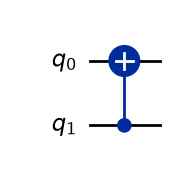

In [8]:
# Registros
quantum_reg_2_qubits = QuantumRegister(2,'q') 

# Circuito
circuit_CNOT = QuantumCircuit(quantum_reg_2_qubits)#, classic_reg_2_bits)
# Añadimos la CNOT
circuit_CNOT.cx(1,0) #(control, target)
circuit_CNOT.draw('mpl',style="iqp")


<IPython.core.display.Latex object>

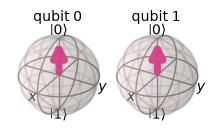

<IPython.core.display.Latex object>

In [9]:
# Simulación de vector de estado
s, c,rs = my_get_circuit_state(circuit_CNOT, shots=1)

# Simulación de matriz unitaria
u, ru = my_get_circuit_unitary(circuit_CNOT)

my_display_state_vector(s,2)

matrix_CNOT = u
array_to_latex(matrix_CNOT, prefix="\\text{CNOT = }\n")

### CNOT con el control LSB 

Veamos un circuito con una puerta CNOT con el control en el bit menos significativo (LSB).
Observa que en el convenio de Qiskit dicho qubit está "arriba".

Fíjate bien en la matriz resultante y compárala con la obtenida anteriormente cuando el controlador es el MSB.

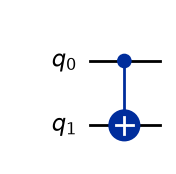

In [10]:
# Circuito
circuit_CNOT_2 = QuantumCircuit(quantum_reg_2_qubits)#, classic_reg_2_bits)
# Añadimos la CNOT
circuit_CNOT_2.cx(0,1) #(control, target)
circuit_CNOT_2.draw('mpl', style="iqp")

<IPython.core.display.Latex object>

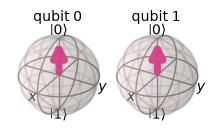

<IPython.core.display.Latex object>

In [11]:
# Simulación de vector de estado
s, c,rs = my_get_circuit_state(circuit_CNOT_2, shots=1)

# Simulación de matriz unitaria
u, ru = my_get_circuit_unitary(circuit_CNOT_2)

my_display_state_vector(s,2)

matrix_CNOT_2 = u
array_to_latex(matrix_CNOT_2, prefix="\\text{CNOT = }")

<div style="border:1pt black solid; padding:3pt;">
    
<b>Ejercicio:</b>

Añade una puerta de SWAP delante la puerta al circuito CNOT con el bit MSB controlando.
Comprueba que la matriz resultante es la misma que la del circuito CNOT con el bit controlador LSB.

</div>

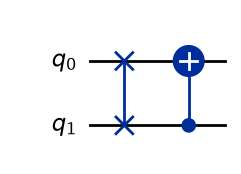

In [12]:
 # Circuito
circuit_CNOT_SWAP = QuantumCircuit(quantum_reg_2_qubits)#, classic_reg_2_bits)
# Añadimos la CNOT
circuit_CNOT_SWAP.swap(quantum_reg_2_qubits[1], quantum_reg_2_qubits[0])
circuit_CNOT_SWAP.cx(1,0) #(control, target)

circuit_CNOT_SWAP.draw('mpl',style="iqp")



<IPython.core.display.Latex object>

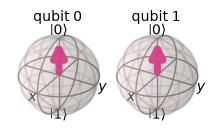

<IPython.core.display.Latex object>

In [13]:
# Simulación de vector de estado
s, c,rs = my_get_circuit_state(circuit_CNOT_SWAP, shots=1)

# Simulación de matriz unitaria
u, ru = my_get_circuit_unitary(circuit_CNOT_SWAP)

my_display_state_vector(s,2)

matrix_CNOT_2 = u
array_to_latex(matrix_CNOT_2, prefix="\\text{CNOT = }")

## Circuitos de dos qúbits con medidores 

### Puerta X y CNOT 

In [14]:
# Registro cuántico
quantum_reg_2_qubits = QuantumRegister(2, 'q') 

# Registro clásico, para medir
classic_reg_2_bits = ClassicalRegister(2, 'c') 

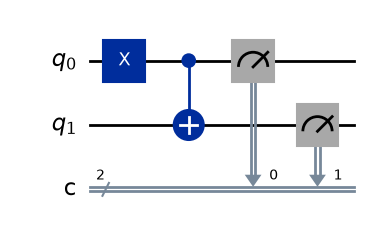

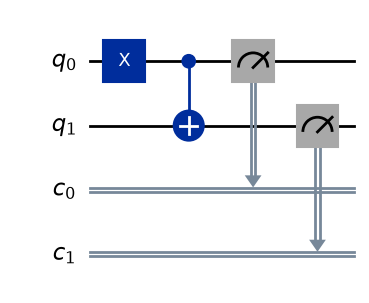

In [15]:
circuit_CNOT_3 = QuantumCircuit(quantum_reg_2_qubits, classic_reg_2_bits)

#################################
# Jugar a comentar y descomentar:
circuit_CNOT_3.x(0)
#circuit_CNOT_3.x(1)
#################################

circuit_CNOT_3.cx(0,1)
circuit_CNOT_3.measure(quantum_reg_2_qubits, classic_reg_2_bits)
display(circuit_CNOT_3.draw('mpl', style="iqp"))

# Para separar los "cables" clásicos usar esta opción de draw
display(circuit_CNOT_3.draw('mpl', style="iqp", cregbundle=False))

<IPython.core.display.Latex object>

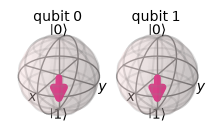

{'11': 1000}

In [16]:
# Simulación de vector de estado
# Utilizar múltiples shots ya que hay medidores
s, c, rs = my_get_circuit_state(circuit_CNOT_3, 1000)

# La simulación unitaria no tiene mucho sentido en
# esta prueba, ya que hemos puesto medidores

my_display_state_vector(s, inches=2)

counts_CNOT_3 = c
display(counts_CNOT_3)

### Puerta Swap   

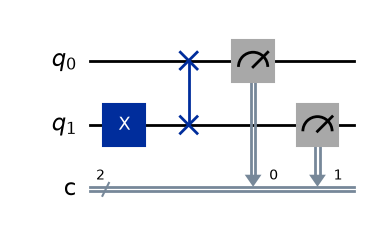

In [17]:
circuit_SWAP = QuantumCircuit(quantum_reg_2_qubits, classic_reg_2_bits)
circuit_SWAP.x(1)
circuit_SWAP.swap(0,1)
circuit_SWAP.measure(quantum_reg_2_qubits, classic_reg_2_bits)
circuit_SWAP.draw('mpl',style="iqp")

{'01': 5000}

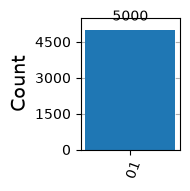

In [18]:
# Simulemos y veamos el histograma

# Simulación de vector de estado
# Utilizar múltiples shots ya que hay medidores
s, c, rs = my_get_circuit_state(circuit_SWAP, shots=5000)

counts_SWAP = c
display(counts_SWAP)
display(plot_histogram(counts_SWAP, figsize=(2,2)))

## El **circuito entrelazador**: $\text{CNOT} \cdot (H\otimes I)$ 

Cuando aplicamos una puerta $H$ sobre un qúbit ponemos este qúbit en una superposisción de $| 0 \rangle$ y $| 1 \rangle$:
$$
H | 0 \rangle = \frac{1}{2} \left( | 0 \rangle + | 1 \rangle \right) 
$$

Si ahora pasamos este estado como **controlador** de una puerta CNOT, podemos generar un estado entrelazado.

En el ejemplo siguiente, generaremos el estado de Bell $B_{00}$ a partir del $|00\rangle$ a través del circuito **entrelazador**.

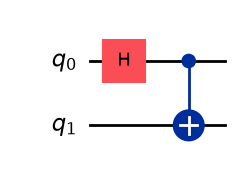

In [19]:
circuit_CNOT_H = QuantumCircuit(quantum_reg_2_qubits)#, classic_reg_2_bits)
circuit_CNOT_H.h(0)
circuit_CNOT_H.cx(0,1)
#circuit_CNOT_H.measure(quantum_reg_2_qubits, classic_reg_2_bits)
circuit_CNOT_H.draw('mpl', style="iqp")

{np.str_('00'): np.float64(0.5), np.str_('11'): np.float64(0.5)}

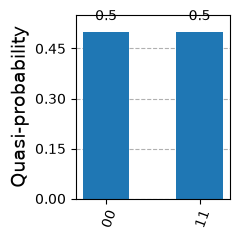

In [20]:
# Simular y dibujar el histograma

# ¡¡ Utilizar múltiples shots ya que hay medidores !!
s, c, rs = my_get_circuit_state(circuit_CNOT_H, shots=5000)

state_CNOT_H = s
counts_CNOT_H = c

display(counts_CNOT_H)
display(plot_histogram(counts_CNOT_H, figsize=(2.5,2.5)))

<IPython.core.display.Latex object>

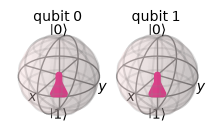

In [21]:
#¡¡Solo sale correcto si es sin medidores el entrelazado!!
my_display_state_vector(state_CNOT_H, inches=2)

Podemos genera otros estados estados entrelazados diferentes
(otros estados de Bell, en particular):

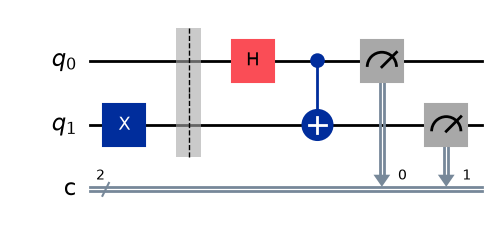

In [23]:
circuit_CNOT_HX = QuantumCircuit(quantum_reg_2_qubits, classic_reg_2_bits)
circuit_CNOT_HX.x(1)
circuit_CNOT_HX.barrier()
circuit_CNOT_HX.h(0)
circuit_CNOT_HX.cx(0,1)
#Cancelar entrelazamiento
#circuit_CNOT_HX.cx(0,1)
#circuit_CNOT_HX.h(0)
circuit_CNOT_HX.measure(quantum_reg_2_qubits, classic_reg_2_bits)
circuit_CNOT_HX.draw('mpl', style="iqp")

{'10': 2474, '01': 2526}

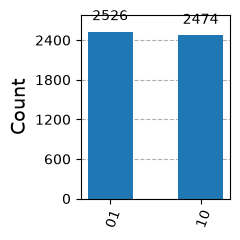

In [24]:
# Simulemos y veamos el histograma

# Simulación de vector de estado
# Utilizar múltiples shots ya que hay medidores
s, c, rs = my_get_circuit_state(circuit_CNOT_HX, shots=5000)

counts_CNOT_HX = c
display(counts_CNOT_HX)
display(plot_histogram(counts_CNOT_HX, figsize=(2.5,2.5)))

## Puertas con más de un qubit controlador

### Puerta CSWAP o de Fredkin 

En este ejemplo también vemos que no es necesario que haya los mismos qúbits en registro cuántico que en el clásico. Además, si queremos podemos medir solo unos cuantos qúbit, no todo

In [25]:
# Registro cuántico de 3 qubits
quantum_reg_3_qubits = QuantumRegister(3, 'q') 
# Registro clásico de 2 qubits
classic_reg_2_bits = ClassicalRegister(2, 'cl') 

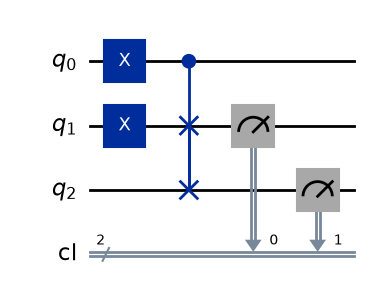

In [26]:
circuit_CSWAP = QuantumCircuit(quantum_reg_3_qubits, classic_reg_2_bits)

#################################
# Jugar a comentar y descomentar:
circuit_CSWAP.x(0)
circuit_CSWAP.x(1)
#################################

circuit_CSWAP.cswap(0,1,2)
circuit_CSWAP.measure(quantum_reg_3_qubits[1:], classic_reg_2_bits)
circuit_CSWAP.draw('mpl',style="iqp")

{'10': 5000}

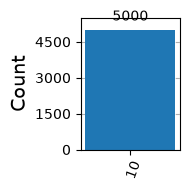

In [27]:
# Simulemos y veamos el histograma

# Simulación de vector de estado
# Utilizar múltiples shots ya que hay medidores
s, c, rs = my_get_circuit_state(circuit_CSWAP, shots=5000)

counts_CSWAP = c
display(counts_CSWAP)
display(plot_histogram(counts_CSWAP, figsize=(2,2)))

### CCNOT o Toffoli   

In [28]:
# Registro cuántico de 3 qubits
quantum_reg_3_qubits = QuantumRegister(3, 'q') 
# Registro clásico de 3 qubits
classic_reg_3_bits = ClassicalRegister(3, 'cl') 

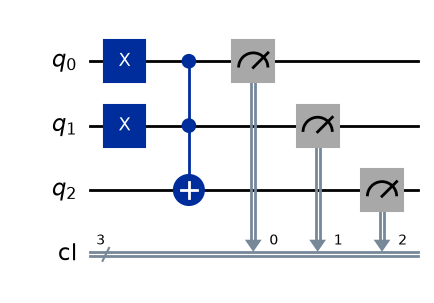

In [29]:
circuit_tof = QuantumCircuit(quantum_reg_3_qubits, classic_reg_3_bits)

#################################
# Jugar a comentar y descomentar una o varias lias:
circuit_tof.x(0)
circuit_tof.x(1)
#################################

circuit_tof.ccx(0,1,2) # Esto es la puerta de TOFFOLI
circuit_tof.measure(quantum_reg_3_qubits, classic_reg_3_bits)
circuit_tof.draw('mpl', style="iqp")

{'111': 5000}

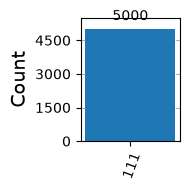

In [30]:
# Simulación e histograma

# Simulación de vector de estado
# Utilizar múltiples shots ya que hay medidores
s, c, rs = my_get_circuit_state(circuit_tof, shots=5000)

counts_tof = c
display(counts_tof)
display(plot_histogram(counts_tof, figsize=(2,2)))

### Puerta MCX (multicontrolada X)  

In [31]:
# Registros cuánticos
control_reg = QuantumRegister(4, 'q') 
target_qubit = QuantumRegister(1, 'y')

# Registro clásico
classic_reg_1_bits = ClassicalRegister(1, 'cl') 

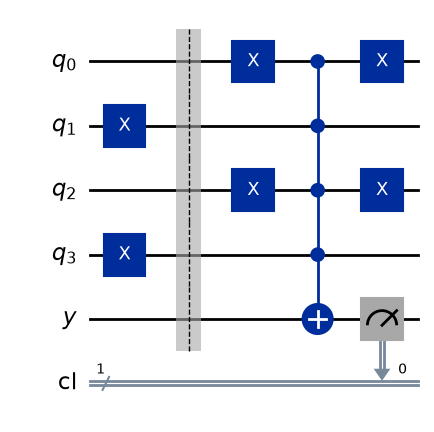

In [32]:
circuit_mcx = QuantumCircuit(control_reg, target_qubit, classic_reg_1_bits)

#################################
# Jugar a comentar y descomentar una o varias lias:
# Inicializacion

#circuit_mcx.x(control_reg[0])
circuit_mcx.x(control_reg[1])
#circuit_mcx.x(control_reg[2])
circuit_mcx.x(control_reg[3])
#################################

circuit_mcx.barrier()

#################################
# Jugar a comentar y descomentar una o varias lias:
# Respetar que en un mismo qubit debe de haber o 
# ninguna X o una antes y otra despues de la mcx

circuit_mcx.x(control_reg[0])
#circuit_mcx.x(control_reg[1])
circuit_mcx.x(control_reg[2])
#circuit_mcx.x(control_reg[3])
#################################

circuit_mcx.mcx(control_reg, target_qubit)

#################################
# Jugar a comentar y descomentar una o varias lias:
# Respetar que en un mismo qubit debe de haber o 
# ninguna X o una antes y otra despues de la mcx

circuit_mcx.x(control_reg[0])
#circuit_mcx.x(control_reg[1])
circuit_mcx.x(control_reg[2])
#circuit_mcx.x(control_reg[3])
#################################

circuit_mcx.measure(target_qubit, classic_reg_1_bits)
circuit_mcx.draw('mpl', style="iqp")

{'1': 5000}

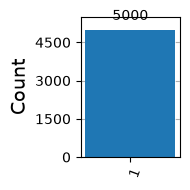

In [33]:
# Simulación e histograma

# Simulación de vector de estado
# Utilizar múltiples shots ya que hay medidores
s, c, rs = my_get_circuit_state(circuit_mcx, shots=5000)

counts_mcx = c
display(counts_mcx)
display(plot_histogram(counts_mcx, figsize=(2,2)))

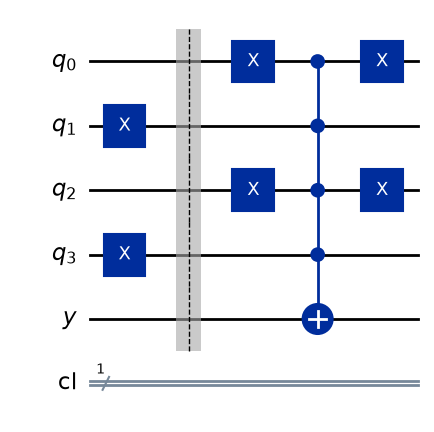

<IPython.core.display.Latex object>

In [34]:
# Vamos a calcular la matriz de este último circuito 

# Pero antes vamos a eliminar el medidor, para ello
# haremos una copia del circuito y recorreremos todas
# sus instrucciones, haciendo una lista de aquellas que
# tengan por nombre 'measure'
circuit_mcx_nomeasure = circuit_mcx.copy()
iidx = 0 # instruction index
lm = []
for g in circuit_mcx_nomeasure.data:
    if g.operation.name == 'measure':
        lm.append(iidx)
    iidx += 1

# Esta es la lista de medidores, vamos a quitarlos
# del circuito con QuantumCircuit.pop()
for iidx in lm:
    circuit_mcx_nomeasure.data.pop(iidx)

# El circuito resultante no debe tener medidores
display(circuit_mcx_nomeasure.draw('mpl', style="iqp"))

# Veamos su matriz unitaria
u, r = my_get_circuit_unitary(circuit_mcx_nomeasure)

matrix_circuit_mcx = u

# Al mostrar la matriz nos saldrá truncada porque es
# muy grande
display(array_to_latex(matrix_circuit_mcx))

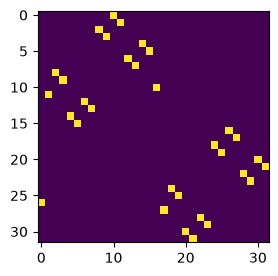

In [35]:
# Como esta matriz es muy grande, vamos a representar como IMAGEN
# Resaltarán aquellos elementos con valores no nulos

plt.figure(figsize=(3,3))
plt.imshow(np.abs(matrix_circuit_mcx.data))
plt.show()

<div style="border:1pt black solid; padding:3pt;">
<b>Ejercicio:</b>

Chequea algunas otras maneras de representar esta matriz. Por ejemplo ```qiskit.visualization``` contiene los métodos ```plot_state_city()``` y ```plot_state_hinton()```. Pruébalos.

👉 No olvidar que para usarlos es necesario importarlos previamente en el _notebook_: 
```python
   from qiskit.visualization import plot_state_city, plot_state_hinton
```
<br>    
</div>

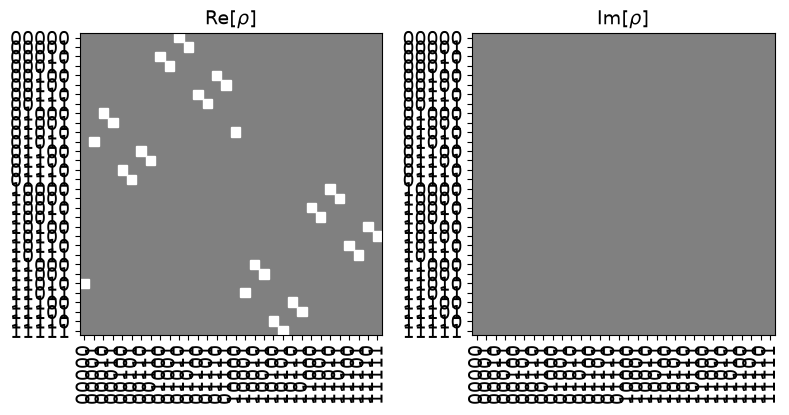

In [40]:
###### Escribe aquí la solución
from qiskit.visualization import plot_state_city, plot_state_hinton
plot_state_hinton(matrix_circuit_mcx)



## Ejercicio: circuito GHZ

<div style="border:1pt black solid; padding:3pt;">

<b>Ejercicio: El estado GHZ</b>

En un cuadernillo anterior se introdujo un popular estado entrelazado de 3 qubits, el estado de __Greenberger–Horne–Zeilinger__ (GHZ), una de cuyas variantes viene definida como:

$$ |\text{GHZ}\rangle = \frac{|000\rangle - |111\rangle}{\sqrt{2}} $$

Se pide:
 - Construir el circuito para su generación
 - Realizar una simulación ideal, sin medidores, para obtener el vector de estado de salida del circuito, y comprobar que el estado GHZ se genera correctamente
 - Modificar el circuito añadiendo medidores estándar a la salida de los qubits de interés
 - Realizar la simulación real con un número de __shots__ suficientemente grande
 - Obtener las frecuencias relativas medidas (probabilidades) y dibujar el histograma del conteo de las mediciones
 - Analizar los resultados, comprobar que se obtiene lo que se espera, y que las mediciones están acorde con el resultado teórico de lápiz y papel

Pista: puede encontrarse una posible solución en este cuadernillo el libro de Qiskit: [https://github.com/Qiskit/textbook/blob/main/notebooks/ch-labs/Lab04_Bell_GHZ_Circuit.ipynb](https://github.com/Qiskit/textbook/blob/main/notebooks/ch-labs/Lab04_Bell_GHZ_Circuit.ipynb)

</div>

<div style="border:1pt black solid; padding:3pt;">

<b>Ejercicio:</b>

Encontramos estas variantes del estado GHZ:
$$\frac{1}{\sqrt{2}}(|000\rangle - |111\rangle)$$
$$\frac{1}{\sqrt{2}}(|000\rangle + |111\rangle)$$

$$\frac{1}{\sqrt{2}}(|001\rangle - |110\rangle)$$
$$\frac{1}{\sqrt{2}}(|001\rangle + |110\rangle)$$

$$\frac{1}{\sqrt{2}}(|010\rangle - |101\rangle)$$
$$\frac{1}{\sqrt{2}}(|010\rangle + |101\rangle)$$

$$\frac{1}{\sqrt{2}}(|100\rangle - |011\rangle)$$
$$\frac{1}{\sqrt{2}}(|100\rangle + |011\rangle)$$

¿Qué modificaciones habría que hacer en el circuito anterior para obtenerlas todas? (la respuesta está en la misma URL anteror del libro de Qiskit)

</div>

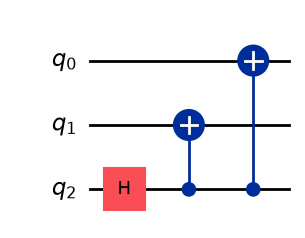

In [37]:
###### Escribe aquí la solución
# Registro cuántico de 3 qubits
quantum_reg_3_qubits = QuantumRegister(3, 'q') 
# Registro clásico de 3 qubits
classic_reg_3_bits = ClassicalRegister(3, 'cl') 

circuit_ghz_shots = QuantumCircuit(quantum_reg_3_qubits, classic_reg_3_bits)
circuit_ghz_god = QuantumCircuit(quantum_reg_3_qubits)

#################################
# Jugar a comentar y descomentar una o varias lias:
circuit_ghz_shots.h(2)
circuit_ghz_god.h(2)

#################################


circuit_ghz_shots.cx(2,1) # Esto es la puerta de TOFFOLI
circuit_ghz_god.cx(2,1) # Esto es la puerta de TOFFOLI


circuit_ghz_shots.cx(2,0) # Esto es la puerta de TOFFOLI
circuit_ghz_god.cx(2,0) # Esto es la puerta de TOFFOLI

circuit_ghz_shots.measure(quantum_reg_3_qubits, classic_reg_3_bits)
circuit_ghz_god.draw('mpl', style="iqp")



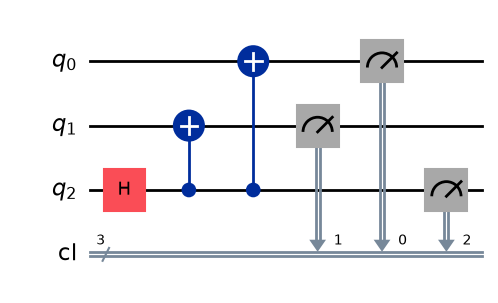

In [38]:
circuit_ghz_shots.draw('mpl', style="iqp")

{'000': 2479, '111': 2521}

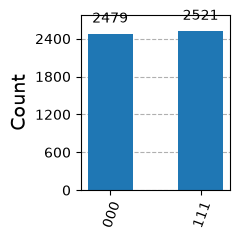

{np.str_('000'): np.float64(0.5), np.str_('111'): np.float64(0.5)}

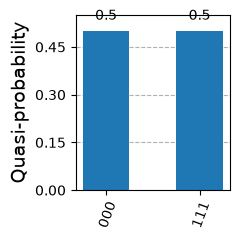

<IPython.core.display.Latex object>

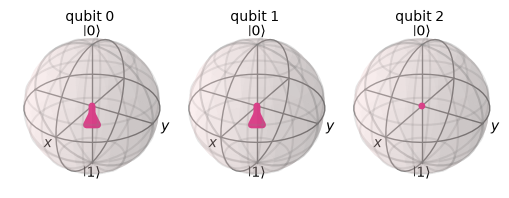

In [39]:

# Simulemos y veamos el histograma

# Simulación de vector de estado
# Utilizar múltiples shots ya que hay medidores
s, c, rs = my_get_circuit_state(circuit_ghz_shots, shots=5000)

counts_ghz = c
display(counts_ghz)
display(plot_histogram(counts_ghz, figsize=(2.5,2.5)))

# Simular y dibujar el histograma

# ¡¡ Utilizar múltiples shots ya que hay medidores !!
s, c, rs = my_get_circuit_state(circuit_ghz_god, shots=5000)

state_ghz_god = s
counts_ghz_god = c

display(counts_ghz_god)
display(plot_histogram(counts_ghz_god, figsize=(2.5,2.5)))

#¡¡Solo sale correcto si es sin medidores el entrelazado!!
my_display_state_vector(state_ghz_god, inches=5)